# Figure 5S3: Conditional Accuracy Functions (MX task, blocks 1–3)

Supplemental to `Figure05_mixedVsBlockedSNR.m`

This is the **conditional accuracy function (CAF)** from the collapsing-bound
literature (e.g. Ditterich 2006, *Eur J Neurosci*): the probability that a decision
terminating at time `t` (here, decision time `DT = t`, in steps) lands on the
rewarded side, `P(correct | DT = t)`, plotted against `t`. This is not overall
accuracy — it conditions specifically on trials that took exactly `t` steps to
decide.

Trial-to-trial variability in drift rate and in bound height make opposite
predictions for the shape of this function:

- **Drift rate varies trial to trial, bound is fixed**: slow-terminating trials
  become progressively enriched for the harder (lower-|SNR|) trials — the easy
  trials have mostly already terminated by then — so CAF should **decline** with
  `t`.
- **Bound also varies trial to trial** (this paper's "flexible decision rule"
  account): extra, SNR-independent trial-to-trial bound variability broadens the
  bound crossed at any given `t`, diluting the low-SNR-enrichment effect above, so
  CAF should be **flatter, or rise**, relative to the fixed-bound case.

The **MX (mixed SNR)** blocks are the natural place to test the first part: two SNR
levels (lo = 1/3, hi = 1) are interleaved trial by trial within a block, so drift
rate genuinely varies from trial to trial by design, and subjects cannot know in
advance which SNR applies on a given trial. Computing CAFs from the model and data
and comparing them is a direct test of the flexible-bound account.

## Interpretation

- **Fixed-bound model** (drift varies only): the DT slope is negative and
  significant in all three blocks (block 1: β=−0.0046, p<0.001; block 2:
  β=−0.0044, p<0.001; block 3: β=−0.0036, p=0.010) — confirming the null
  prediction that trial-to-trial drift-rate variability alone produces a
  declining CAF.
- **Variable-bound model** (drift and bound both vary, using each subject's own
  empirical bound SD): the decline is eliminated in every block (block 1:
  β=+0.0015, p=0.235; block 2: β=−0.0008, p=0.506; block 3: β=+0.0009, p=0.528) —
  none differ significantly from flat, confirming that realistic trial-to-trial
  bound variability offsets the drift-driven decline, as the theoretical logic
  above predicts.
- **Real data**: significantly declining in blocks 1–2 (β=−0.013, p=0.034;
  β=−0.010, p=0.033) and flat in block 3 (β=−0.004, p=0.554).

The theoretical logic holds within the models themselves: bound variability at
the magnitude actually observed in subjects' data is enough to flatten (and even
slightly reverse) the decline that drift variability alone predicts. Block 3's
real CAF matches this flattened prediction. Blocks 1 and 2, however, decline more
steeply than either model — including the variable-bound model — so this
analysis does not cleanly resolve in favor of the flexible-bound account in every
block. It confirms the predicted qualitative signature is real and detectable,
and it identifies blocks 1–2 as showing additional decline beyond what
per-block bound variability alone captures (e.g. within-block drift in the bound
over the course of a block, or genuine within-trial urgency — neither of which
this model includes).

## What this notebook does

For each of MX blocks 1–3, computes the empirical CAF (pooled across subjects,
DT = 3–10 steps — the range with enough trials per bin to be stable) and compares
it against two matched simulations, both built from each subject's own real,
mixed lo/hi generative SNRs, differing only in how the bound is simulated:

1. **Fixed-bound model** (`bound_type='fixed'`): each subject's single, SNR-blind
   median |bound| in that block, held constant across trials — i.e. drift varies,
   bound does not. Predicts a **falling** CAF.
2. **Variable-bound model** (`bound_type='var'`): each subject's own median
   *and* SD of |bound| in that block, so the simulated bound itself varies
   trial to trial (by the same amount real subjects' bound estimates vary),
   independently of which SNR that trial happens to be. Predicts a **flatter, or
   rising**, CAF relative to the fixed-bound model.

Each model is simulated `N_REPS` times per subject (independent replicate blocks,
same 600-step budget as a real block) and pooled, to average out simulation noise
without inflating a single replicate beyond a real block's length. A linear
regression of `correct ~ DT` (pooled trials, restricted to the plotted DT range)
gives a per-source, per-block slope, intercept, and p-value — plotted directly as
the regression line in the figure below, and the direct test of whether CAF rises
or falls.

**Data**: MX task, blocks 1–3, `DT > 2` (keeps DT ≥ 3), all subjects, both SNR
levels pooled together — that mixture is exactly what creates the conditioning
effect being tested.

## Imports

Standard scientific Python libraries plus `get_data_table` / `get_good_trial_array`
from `pigeon.data`, `get_bound_summary` from `pigeon.stats`, and
`get_simulated_data_table` from `pigeon.simulate`. Uses `scipy.stats.linregress`
for the linear-regression slope test.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

from pigeon.data import get_data_table, get_good_trial_array
from pigeon.stats import get_bound_summary
from pigeon.simulate import get_simulated_data_table
from pigeon.pathDefaults import FIGURES_DIR

## Load data

Loads all MX (mixed-SNR) trials via `get_data_table(task_type='MX')`.

In [2]:
data_table_mx = get_data_table(task_type='MX')

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_09h13.45.625.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h11.56.537.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h12.28.806.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.05.149.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.09.605.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.30.507.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.32.506.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.16.148.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.31.520.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.41.484.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h14.52.557.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h18.44.254.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h19.33.518.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h28.25.851.csv
 22: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.43.591.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.53.031.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.00.949.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.12.054.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.15.803.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.22.933.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.24.102.csv
 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 41: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h23.15.258.csv
 42: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h23.37.400.csv
 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h29.44.495.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.06.340.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.07.354.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.12.482.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.49.710.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 54: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h19.57.520.csv
 55: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h26.10.569.csv
 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h49.58.399.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h53.32.854.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_19h25.58.493.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-12-06_12h13.32.209.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-12-06_15h08.34.504.csv


## Parameters and helper functions

**`MIN_DT`**: pre-filter `DT > 2` (keeps DT ≥ 3), matching the convention used in
`Figure05_mixedVsBlockedSNR` and its supplements.

**`DT_VALS`**: DT = 3–10 steps. Chosen empirically: every block has ≥ 20 real
pooled trials at every DT in this range (`MIN_POOLED_N`), and counts fall off
sharply beyond DT=10 — this is the stable, well-sampled range analyzed below.

**`N_REPS`**: number of independent simulated-block replicates per subject per
model (each replicate uses the same 600-step block budget as a real block).
Pooled across replicates to smooth out simulation noise while preserving the same
finite-block structure as the real data.

**`good_dt_correct`**: `DT`/`correct` columns for good trials in one block.

**`dt_counts`**: pooled (n_trials, n_correct) per DT bin.

**`clopper_pearson`**: 50% CI (25th/75th percentile of the beta posterior) on the
pooled proportion at each DT bin — same convention as Figure02/Figure03's
accuracy error bars.

**`dt_slope`**: trial-level linear regression (`scipy.stats.linregress`) of
`correct` on `DT`, restricted to `DT_VALS`. The sign and significance of the slope
is the direct test of "CAF rises vs. falls," and the fitted line is what's drawn
in the figure below.

In [3]:
MIN_DT         = 2                       # keep DT > 2 (i.e. DT >= 3)
DT_VALS        = np.arange(3, 11)        # DT = 3-10 steps: stable, well-sampled range
MIN_POOLED_N   = 20                      # min real pooled trials per DT bin to trust it
N_REPS         = 20                      # simulated-block replicates per subject per model
BLOCKS         = [1, 2, 3]

RNG = np.random.default_rng(20260702)


def good_dt_correct(data_table, block, min_dt=MIN_DT):
    """DT/correct columns for good trials in `block`, DT > min_dt."""
    lg = get_good_trial_array(data_table, block_index=block) & (data_table['DT'] > min_dt)
    return data_table.loc[lg, ['DT', 'correct']].dropna().reset_index(drop=True)


def dt_counts(df, dt_vals):
    """Pooled (n_trials, n_correct) per DT bin."""
    n = np.array([int((df['DT'] == dt).sum()) for dt in dt_vals])
    k = np.array([int(df.loc[df['DT'] == dt, 'correct'].sum()) for dt in dt_vals])
    return n, k


def clopper_pearson(k, n, ci=0.5):
    """50% CI (Clopper-Pearson) on k/n, matching Figure02/Figure03's convention."""
    lo_q, hi_q = (1 - ci) / 2, 1 - (1 - ci) / 2
    lo = np.full(len(k), np.nan)
    hi = np.full(len(k), np.nan)
    for i in range(len(k)):
        if n[i] > 0:
            lo[i] = scipy.stats.beta.ppf(lo_q, k[i],     n[i] - k[i] + 1)
            hi[i] = scipy.stats.beta.ppf(hi_q, k[i] + 1, n[i] - k[i])
    return lo, hi


def dt_slope(df, dt_vals):
    """Linear regression of correct ~ DT, restricted to dt_vals."""
    sub = df[df['DT'].isin(dt_vals)]
    fit = scipy.stats.linregress(sub['DT'], sub['correct'])
    return fit.slope, fit.intercept, fit.pvalue, len(sub)

## Compute real and model CAFs

For each block: pooled real trial-level (DT, correct) data; pooled data from
`N_REPS` fixed-bound-model replicates per subject (drift varies via the real
mixed SNRs, bound fixed to each subject's own median |bound|); and pooled data
from `N_REPS` variable-bound-model replicates per subject (same real mixed SNRs,
but the bound itself is redrawn per trial from each subject's own median ± SD of
|bound| in that block — `bound_type='var'`). Both models are built directly from
each real subject's own block-level data via `get_simulated_data_table`, so every
subject contributes to both models (no subject-exclusion step is needed here,
unlike a per-SNR bound fit).

In [4]:
results = {}

for block in BLOCKS:
    real_block = data_table_mx[data_table_mx['block_index'] == block].reset_index(drop=True)

    df_real = good_dt_correct(data_table_mx, block)

    # Model (a): fixed bound, real mixed-SNR drift ("drift varies" null)
    fix_frames = []
    for _ in range(N_REPS):
        sim_fix = get_simulated_data_table(
            data_table=real_block, bound_type='fixed', correct_bias=None, rng=RNG)
        fix_frames.append(good_dt_correct(sim_fix, block))
    df_fix = pd.concat(fix_frames, ignore_index=True)

    # Model (b): variable bound (median +/- SD of each subject's own |bound| in this
    # block), real mixed-SNR drift -- both drift and bound vary trial to trial.
    var_frames = []
    for _ in range(N_REPS):
        sim_var = get_simulated_data_table(
            data_table=real_block, bound_type='var', correct_bias=None, rng=RNG)
        var_frames.append(good_dt_correct(sim_var, block))
    df_var = pd.concat(var_frames, ignore_index=True)

    results[block] = dict(df_real=df_real, df_fix=df_fix, df_var=df_var)

    n_real, _ = dt_counts(df_real, DT_VALS)
    print(f'Block {block}: {len(df_real)} real trials (DT > {MIN_DT})')
    below = DT_VALS[n_real < MIN_POOLED_N]
    if len(below):
        print(f'  Warning: DT bins below MIN_POOLED_N={MIN_POOLED_N}: {below.tolist()}')

Block 1: 1806 real trials (DT > 2)


Block 2: 2085 real trials (DT > 2)


Block 3: 1086 real trials (DT > 2)


## Regression test: does CAF rise or fall?

Linear regression of `correct ~ DT` (pooled trials, `DT_VALS` only) for the real
data and each model. A negative, significant slope means accuracy declines with
decision time (the drift-varies prediction); a slope at or above zero means it's
flat or rising (the bound-varies prediction). These are the same fitted lines
drawn in the figure below.

In [5]:
print(f'{"block":>6} {"source":>10} {"slope":>9} {"p":>10} {"n trials":>10}')
for block in BLOCKS:
    r = results[block]
    r['stats'] = {}
    for label, key, df in [('real', 'real', r['df_real']),
                            ('fixed', 'fix', r['df_fix']),
                            ('variable', 'var', r['df_var'])]:
        slope, intercept, p, n = dt_slope(df, DT_VALS)
        r['stats'][key] = dict(slope=slope, intercept=intercept, p=p, n=n)
        print(f'{block:>6} {label:>10} {slope:>9.4f} {p:>10.3g} {n:>10}')
    print()

 block     source     slope          p   n trials
     1       real   -0.0130     0.0339       1763
     1      fixed   -0.0046   0.000588      22680
     1   variable    0.0015      0.235      20221

     2       real   -0.0103     0.0333       1954
     2      fixed   -0.0044   7.81e-05      26601
     2   variable   -0.0008      0.506      21645

     3       real   -0.0037      0.554       1014
     3      fixed   -0.0036     0.0101      15965
     3   variable    0.0009      0.528      12425



## Figure

One panel per block: pooled real CAF (black) vs. the fixed-bound model (blue —
drift varies, bound fixed) vs. the variable-bound model (orange — drift varies
and bound varies, matched to each subject's own bound SD). Points + 50% CI show
the binned data for all three sources; the straight lines are each source's own
linear regression fit (from `dt_slope` above), with the fitted slope and p-value
in the legend. Dotted horizontal line at chance (0.5). Saves to `Figure05_S03.pdf`.

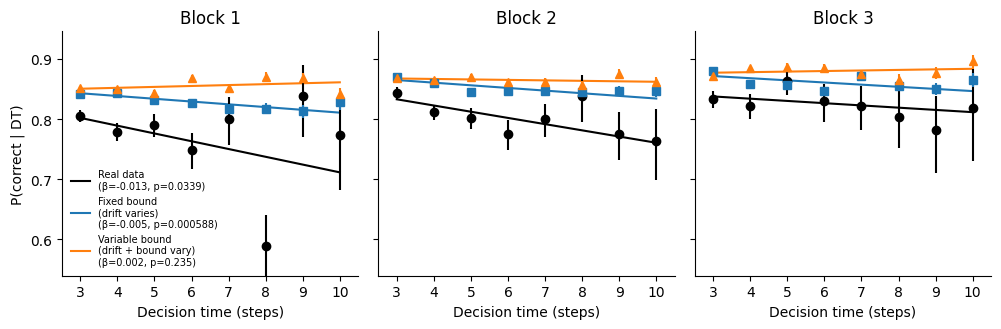

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05_S03.pdf


In [6]:
COLOR_REAL = 'k'
COLOR_FIX  = 'tab:blue'
COLOR_VAR  = 'tab:orange'

SOURCES = [
    ('Real data',                       'real', COLOR_REAL, 'o'),
    ('Fixed bound\n(drift varies)',     'fix',  COLOR_FIX,  's'),
    ('Variable bound\n(drift + bound vary)', 'var', COLOR_VAR, '^'),
]

all_acc = []
for block in BLOCKS:
    r = results[block]
    for df in (r['df_real'], r['df_fix'], r['df_var']):
        n, k = dt_counts(df, DT_VALS)
        ok = n > 0
        all_acc.append(k[ok] / n[ok])
all_acc = np.concatenate(all_acc)
YLIM = (max(0.0, np.nanmin(all_acc) - 0.05), min(1.02, np.nanmax(all_acc) + 0.05))

fig, axs = plt.subplots(1, len(BLOCKS), figsize=(3.4 * len(BLOCKS), 3.4), sharey=True)

for j, block in enumerate(BLOCKS):
    ax = axs[j]
    r = results[block]

    ax.axhline(0.5, color='k', linestyle=':', linewidth=1, zorder=0)

    for label, key, color, marker in SOURCES:
        df = r[f'df_{key}']
        n, k = dt_counts(df, DT_VALS)
        acc = k / n
        lo, hi = clopper_pearson(k, n)
        ax.errorbar(DT_VALS, acc, yerr=[acc - lo, hi - acc],
                    fmt=marker, color=color, markerfacecolor=color, capsize=0,
                    linewidth=0, elinewidth=1.5, markersize=6, zorder=3)

        s = r['stats'][key]
        x_line = np.array([DT_VALS[0], DT_VALS[-1]])
        y_line = s['intercept'] + s['slope'] * x_line
        ax.plot(x_line, y_line, '-', color=color, linewidth=1.5, zorder=2,
                label=f"{label}\n(β={s['slope']:.3f}, p={s['p']:.3g})")

    ax.set_xlim(DT_VALS[0] - 0.5, DT_VALS[-1] + 0.5)
    ax.set_ylim(*YLIM)
    ax.set_xticks(DT_VALS)
    ax.set_title(f'Block {block}')
    ax.set_xlabel('Decision time (steps)')
    if j == 0:
        ax.set_ylabel('P(correct | DT)')
        ax.legend(loc='lower left', fontsize=7, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
out = FIGURES_DIR / 'Figure05_S03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')